<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Experiment 10: L2, Dropout, and Early Stopping Comparison
**Problem Statement:** A medical-records team trained a large MLP that scores 99% on training data but performs poorly on new patients. We will use a small tabular dataset (around 500 records) for predicting diabetes onset from clinical features to compare L2 regularisation, dropout, and early stopping as remedies for overfitting.
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate/simulate a small clinical tabular dataset for diabetes prediction
X, y = make_classification(
    n_samples=500,
    n_features=8,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

# Split into Train and Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (350, 8)
Testing set shape: (150, 8)


```markdown
## Task 1: Train a deliberately large baseline MLP and plot its overfitting
```

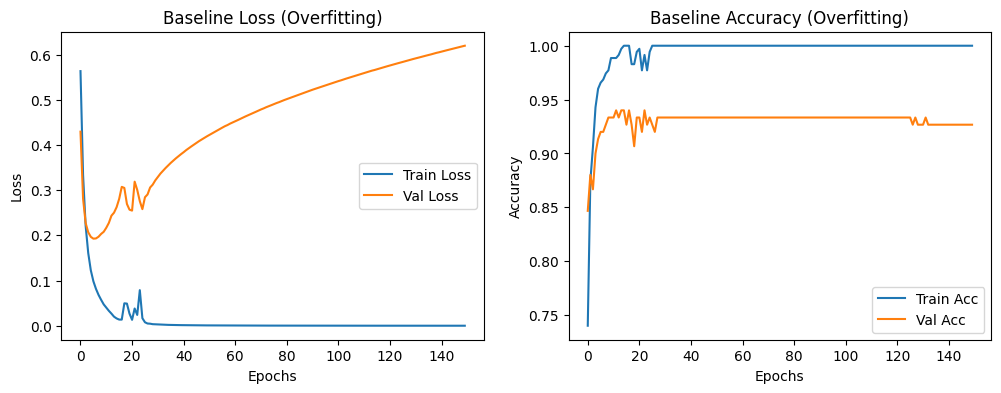

In [2]:
def build_large_mlp(regularizer=None, dropout_rate=0.0):
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train.shape[1],)))

    # Highly overparameterized layers for a 500-sample dataset
    model.add(layers.Dense(256, activation='relu', kernel_regularizer=regularizer))
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(128, activation='relu', kernel_regularizer=regularizer))
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(64, activation='relu', kernel_regularizer=regularizer))
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Train Baseline
baseline_model = build_large_mlp()
history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=150,
    batch_size=16,
    verbose=0
)

# Plot baseline results
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_baseline.history['loss'], label='Train Loss')
plt.plot(history_baseline.history['val_loss'], label='Val Loss')
plt.title('Baseline Loss (Overfitting)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history['accuracy'], label='Train Acc')
plt.plot(history_baseline.history['val_accuracy'], label='Val Acc')
plt.title('Baseline Accuracy (Overfitting)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

```markdown
## Tasks 2, 3, 4 & 5: Train Regularized Variants and Build Comparison Table
```

In [3]:
results = []

def record_metrics(name, model, history):
    train_acc = history.history['accuracy'][-1]
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    gap = train_acc - test_acc
    results.append({
        'Model': name,
        'Train Accuracy': round(train_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'Train-Test Gap': round(gap, 4)
    })

# Record Baseline
record_metrics('Baseline (Overfitted)', baseline_model, history_baseline)

# 2. L2 Regularisation at three lambda values
l2_lambdas = [0.001, 0.01, 0.1]
for lam in l2_lambdas:
    model_l2 = build_large_mlp(regularizer=regularizers.l2(lam))
    history_l2 = model_l2.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=150,
        batch_size=16,
        verbose=0
    )
    record_metrics(f'L2 (lambda={lam})', model_l2, history_l2)

# 3. Dropout at rates 0.2, 0.3, and 0.5
dropout_rates = [0.2, 0.3, 0.5]
for rate in dropout_rates:
    model_do = build_large_mlp(dropout_rate=rate)
    history_do = model_do.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=150,
        batch_size=16,
        verbose=0
    )
    record_metrics(f'Dropout (rate={rate})', model_do, history_do)

# 4. Early Stopping using validation loss
es_callback = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)
model_es = build_large_mlp()
history_es = model_es.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=150,
    batch_size=16,
    callbacks=[es_callback],
    verbose=0
)
record_metrics('Early Stopping', model_es, history_es)

# 5. Display tabular comparison
df_results = pd.DataFrame(results)
display(df_results)

,Model,Train Accuracy,Test Accuracy,Train-Test Gap
0,Baseline (Overfitted),1.0000,0.9267,0.0733
1,L2 (lambda=0.001),0.9971,0.9400,0.0571
2,L2 (lambda=0.01),0.9914,0.9267,0.0648
3,L2 (lambda=0.1),0.5114,0.4800,0.0314
4,Dropout (rate=0.2),0.9943,0.9333,0.0610
5,Dropout (rate=0.3),0.9886,0.9400,0.0486
6,Dropout (rate=0.5),0.9829,0.9267,0.0562
7,Early Stopping,0.9971,0.9200,0.0771
